# Drift detection and visualisation with clustering

This notebook walks through `ClusterBasedDriftDetector`: how to run it, what every result attribute contains and how to plot the clusters. It then runs the detector on synthetic datasets with different numbers of features and drifting features.

The method is described in detail in `docs/user-guide/clustering-dynamics.md`; a comparison with the descriptive-statistics and statistical-test detectors is in `clustering_experiments.ipynb`.

**Running.** Use the project environment (`bachelor_venv`) as the kernel, from the repository root or from `notebooks/`. A full run takes about a minute.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import stride  # noqa: F401
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))

from stride.datasets import get_dataset
from stride.xai.clustering import (
    ClusterBasedDriftDetector,
    plot_centers_shift,
    plot_clusters_by_class,
    plot_drift_clustered,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 200)


def load_blocks(dataset, size_of_block=1000, **params):
    """Generate `size_of_block` samples before and after the drift and split them into two blocks."""
    X, y = get_dataset(dataset).generate(n_samples_before=size_of_block, n_samples_after=size_of_block, **params)
    y = pd.Series(np.asarray(y), name="label")
    before, after = slice(0, size_of_block), slice(size_of_block, 2 * size_of_block)
    return (
        X.iloc[before].reset_index(drop=True),
        y.iloc[before].reset_index(drop=True),
        X.iloc[after].reset_index(drop=True),
        y.iloc[after].reset_index(drop=True),
    )


def show(fig):
    """Display a figure where it is created instead of at the end of the cell."""
    display(fig)
    plt.close(fig)

## 2. Drift detection with clustering

`ClusterBasedDriftDetector` compares a **reference block** (before the drift) with a **detection block** (after it), separately for every class:

1. Features are standardised with the statistics of the reference block.
2. **X-Means** finds the clusters of each class in the reference block; the number of clusters is chosen by BIC between `k_init` and `k_max`.
3. Every detection-block sample is **assigned to the nearest reference centroid** of its class, so both blocks are compared on the same partition. A cluster of the detection block made mostly of samples far from every reference centroid has **appeared**; a reference cluster that receives significantly fewer samples than expected has **disappeared**.
4. Four criteria are checked: appeared/disappeared clusters, centroid shift, change of the per-cluster mean/median/standard deviation (in standard deviations of the feature) and change of the spread (mean distance to the centroid).
5. The **drift strength** is the weighted share of triggered checks. A **permutation test** — re-splitting the pooled samples of both blocks at random — gives the distribution of the strength without drift; drift is reported when the p-value is below `permutation_alpha` (0.05).

### 2.1. Example

A Hyperplane stream with 3 features, 2 of which drift. With an abrupt drift the generator keeps the same feature values after the drift and only the decision boundary — and therefore the labels — changes, i.e. pure concept drift.

In [2]:
X_old, y_old, X_new, y_new = load_blocks("hyperplane_drift", n_features=3, n_drift_features=2)

CBDD = ClusterBasedDriftDetector(X_old, y_old, X_new, y_new, random_state=42)
drift_flag, details = CBDD.detect()

labels_old = CBDD.cluster_labels_old
labels_new = CBDD.cluster_labels_new

### 2.2. Decision

`drift_flag` is the decision of the permutation test, `strength_of_drift` the weighted share of triggered checks (between 0 and 1) and `p_value` the share of random re-splits whose strength is at least the observed one.

In [3]:
print(f"Drift detected: {CBDD.drift_flag}")
print(f"Strength of drift: {CBDD.strength_of_drift:.3f}")
print(f"Permutation p-value: {CBDD.p_value:.3f} ({len(CBDD.null_strengths)} permutations)")

Drift detected: True
Strength of drift: 0.818
Permutation p-value: 0.020 (50 permutations)


`null_strengths` holds the strengths of the permuted blocks. The drift strength is meaningful only relative to this distribution: its value without drift depends on the data (number of features, clusters, block size).

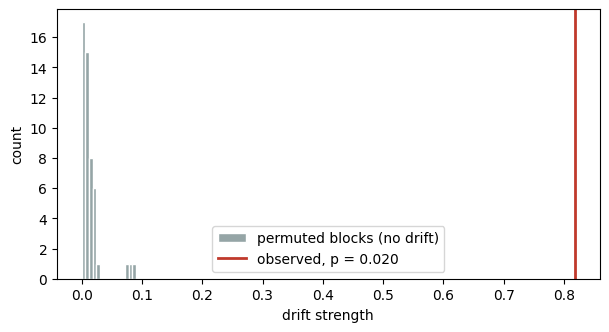

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(CBDD.null_strengths, bins=15, color="#95a5a6", edgecolor="white", label="permuted blocks (no drift)")
ax.axvline(CBDD.strength_of_drift, color="#c0392b", lw=2, label=f"observed, p = {CBDD.p_value:.3f}")
ax.set_xlabel("drift strength")
ax.set_ylabel("count")
ax.legend()
show(fig)

### 2.3. Clusters

Cluster IDs are global: the reference clusters are numbered 0 … n-1 (grouped by class) and keep their ID in the detection block; clusters that appear only in the detection block are numbered from n. `cluster_shifts` gives the status of every cluster — a displacement for tracked clusters, `"appeared"` or `"disappeared"` otherwise.

In [5]:
print(f"Clusters in the reference block: {CBDD.number_of_clusters_old}")
print(f"Clusters in the detection block: {CBDD.number_of_clusters_new}")


def cluster_overview(detector):
    y_old, y_new = np.asarray(detector.y_old), np.asarray(detector.y_new)
    rows = []
    for k, shift in sorted(detector.cluster_shifts.items()):
        in_old, in_new = detector.cluster_labels_old == k, detector.cluster_labels_new == k
        rows.append(
            {
                "cluster": int(k),
                "class": (y_old[in_old] if in_old.any() else y_new[in_new])[0],
                "n before": int(in_old.sum()),
                "n after": int(in_new.sum()),
                "status": shift if isinstance(shift, str) else "tracked",
            }
        )
    return pd.DataFrame(rows).set_index("cluster")


cluster_overview(CBDD)

Clusters in the reference block: 7
Clusters in the detection block: 7


,class,n before,n after,status
cluster,,,,
0,0,133,89,tracked
1,0,147,0,disappeared
2,0,101,0,disappeared
3,0,120,81,tracked
4,1,147,0,disappeared
5,1,167,194,tracked
6,1,185,64,tracked
7,0,0,175,appeared
8,0,0,173,appeared


### 2.4. Descriptive statistics per cluster

`stats_combined` holds the mean, median and standard deviation of every feature in every cluster, before and after (in standardised units; `NaN` where the cluster is absent from a block).

In [6]:
CBDD.stats_combined.sort_index().rename_axis("cluster")

before                                                          after  \
            X1                   X2                   X3                   X1   
          mean median    std   mean median    std   mean median    std   mean   
cluster                                                                         
0       -0.411 -0.323  0.670 -0.964 -0.982  0.496 -0.934 -0.945  0.490 -0.384   
1       -0.564 -0.564  0.734  0.854  0.821  0.540 -0.984 -1.064  0.462    NaN   
2       -1.037 -1.107  0.617  0.922  0.934  0.525  0.722  0.616  0.524    NaN   
3       -1.068 -1.073  0.495 -0.809 -0.785  0.485  0.733  0.692  0.516 -0.734   
4        1.107  1.131  0.429  0.353  0.391  0.768 -0.947 -0.946  0.459    NaN   
5        0.559  0.593  0.629  0.794  0.804  0.559  0.938  1.024  0.513 -0.444   
6        0.618  0.644  0.678 -0.962 -0.976  0.473  0.490  0.571  0.754 -0.979   
7          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.892   
8          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.836   
9          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN -0.259   

                                                                 
                          X2                   X3                
        median    std   mean median    std   mean median    std  
cluster                                                          
0       -0.323  0.638 -1.181 -1.305  0.430 -0.619 -0.628  0.546  
1          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  
2          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  
3       -0.769  0.559 -1.046 -1.099  0.493  0.787  0.731  0.531  
4          NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  
5       -0.572  0.912  0.873  0.893  0.573  0.867  0.916  0.514  
6       -1.123  0.716 -0.752 -0.686  0.443  0.700  0.647  0.470  
7        0.982  0.552 -0.179 -0.183  0.834  0.889  0.837  0.494  
8        0.915  0.617 -0.119 -0.150  0.870 -0.999 -1.055  0.457  
9       -0.306  0.938  0.538  0.631  0.867 -0.913 -0.935  0.469

`stats_shifts` holds the change of these statistics, **in standard deviations of the feature** (after − before). A change counts as drift when its absolute value exceeds `thr_desc_stats` (0.2 by default).

In [7]:
stats_shifts = pd.DataFrame.from_dict(
    {(int(k), f): s for k, per_feature in CBDD.stats_shifts.items() for f, s in per_feature.items()}, orient="index"
).dropna()
stats_shifts.index.names = ["cluster", "feature"]
stats_shifts.sort_index().style.format("{:+.3f}").map(
    lambda v: "font-weight: bold; color: #c0392b" if abs(v) > CBDD.thr_desc_stats else ""
)

### 2.5. Centroid shifts

For every tracked cluster, `cluster_shifts` stores the Euclidean distance between the centroids and the displacement along each feature, in standardised units. The threshold `thr_centroid_shift` is scaled by $\sqrt{d}$ for $d$ features.

In [8]:
centroid_shifts = pd.DataFrame(
    {
        int(k): {"euclidean distance": s["euclidean_distance"], **dict(zip(CBDD.columns, s["distance_per_feature"]))}
        for k, s in CBDD.cluster_shifts.items()
        if isinstance(s, dict)
    }
).T.sort_index()
centroid_shifts.index.name = "cluster"
print(f"Threshold: {CBDD.thr_centroid_shift:.3f}")
centroid_shifts

Threshold: 0.260


,euclidean distance,X1,X2,X3
cluster,,,,
0,0.384,0.027,-0.217,0.315
3,0.413,0.334,-0.238,0.055
5,1.009,-1.004,0.079,-0.071
6,1.624,-1.597,0.210,0.210


### 2.6. Spread of the clusters

Mean distance of the samples to their centroid in each block, and its relative change. A change larger than `thr_avg_distance_to_center_change` (10%) counts as drift.

In [9]:
spread = pd.DataFrame(
    {
        "before": pd.Series(CBDD.avg_distance_old),
        "after": pd.Series(CBDD.avg_distance_new),
        "relative change": pd.Series(CBDD.avg_distance_shift),
    }
).sort_index()
spread.index = spread.index.astype(int)
spread.index.name = "cluster"
spread.style.format("{:.3f}", na_rep="–").format("{:+.1%}", subset=["relative change"], na_rep="–")

,before,after,relative change
cluster,,,
0,0.920,0.889,-3.3%
1,0.956,–,–
2,0.878,–,–
3,0.805,0.851,+5.7%
4,0.921,–,–
5,0.937,1.125,+20.0%
6,1.033,0.854,-17.3%
7,–,1.033,–
8,–,1.064,–


### 2.7. Triggered checks

`drift_details` holds the True/False flag of every check, per class. The strength combines the share of triggered checks of each criterion with `effective_weights` — the `weights` renormalised over the criteria that could be evaluated.

In [10]:
def criteria_overview(detector):
    def ratio(flags):
        flags = list(flags)
        return f"{sum(flags)}/{len(flags)}"

    rows = {}
    for cl, d in detector.drift_details.items():
        stats = [v for per_feature in d["desc_stats_changes"].values() for s in per_feature.values() for v in s.values()]
        rows[cl] = {
            "clusters appeared/disappeared": bool(d["nr_of_clusters"]),
            "centroid shift": ratio(d["centroid_shift"].values()),
            "descriptive statistics": ratio(stats),
            "spread": ratio(d["avg_distance_to_center"].values()),
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("class")


criteria = ["clusters appeared/disappeared", "centroid shift", "descriptive statistics", "spread"]
print("Effective weights:", {c: round(float(w), 3) for c, w in zip(criteria, CBDD.effective_weights)})
criteria_overview(CBDD)

Effective weights: {'clusters appeared/disappeared': 0.4, 'centroid shift': 0.25, 'descriptive statistics': 0.25, 'spread': 0.1}


,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,2/2,8/18,0/2
1,True,2/2,9/18,2/2


## 3. Visualisation

The plots use the original (unscaled) features. With more than two features the data are projected on the first two principal components (PCA fitted on the reference block), so distances in the plots are only approximate. Cluster colours are the same in all plots.

### 3.1. Clusters of both blocks, all classes together

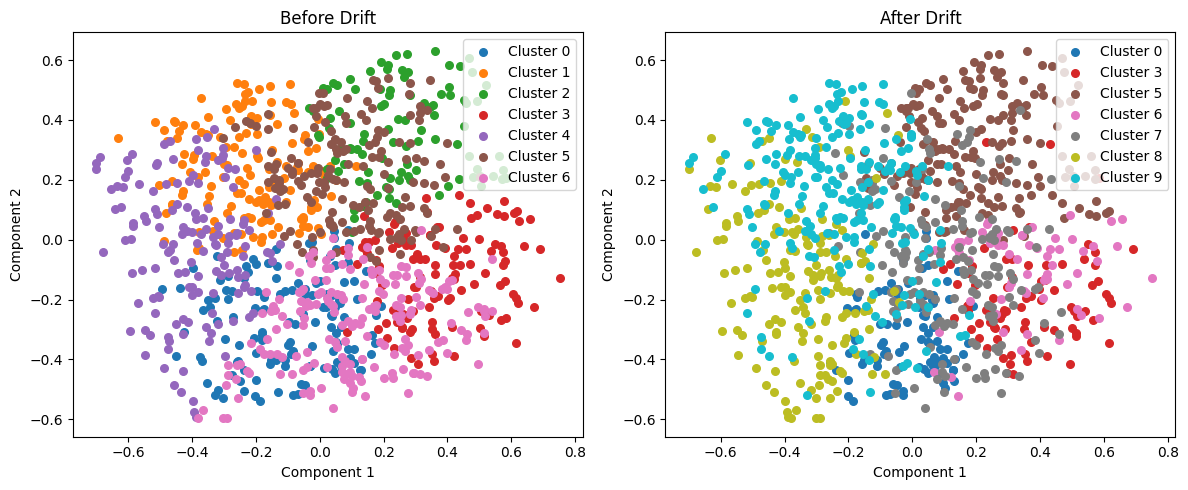

In [11]:
show(plot_drift_clustered(X_old, X_new, y_old, y_new, labels_old, labels_new))

### 3.2. Clusters of each class separately

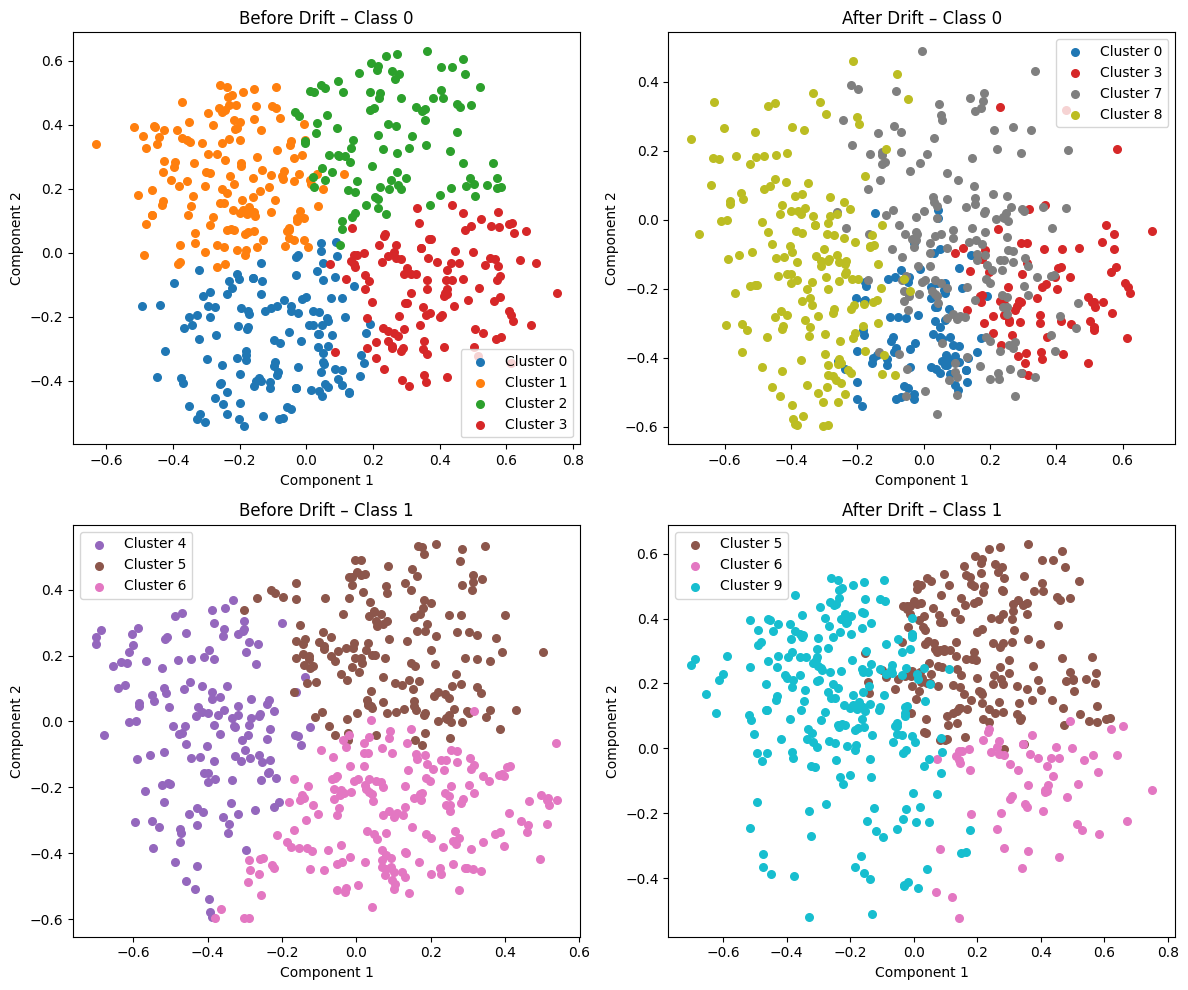

In [12]:
show(plot_clusters_by_class(X_old, X_new, y_old, y_new, labels_old, labels_new))

### 3.3. Centroid shifts

Crosses are the centroids in the reference block, dots in the detection block; a dashed line connects the centroids of a tracked cluster.

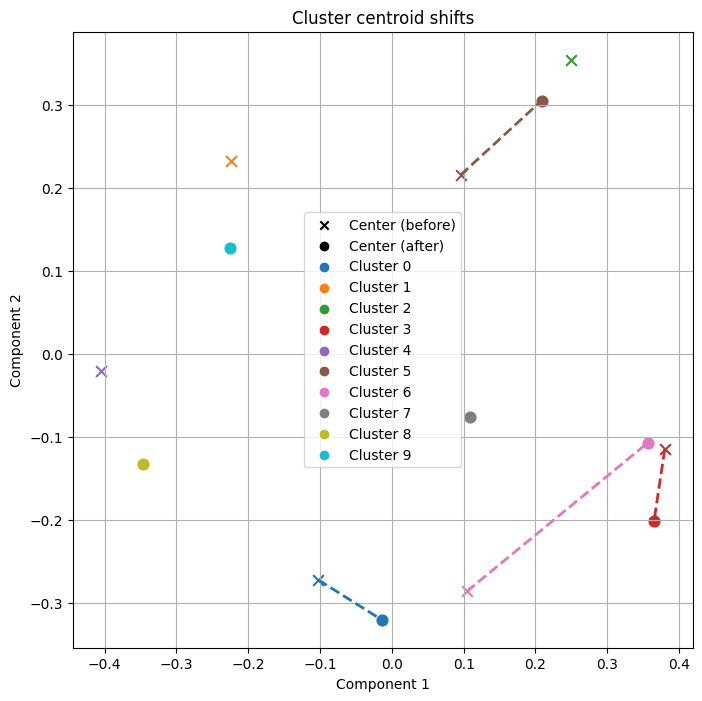

In [13]:
show(plot_centers_shift(X_old, X_new, y_old, y_new, labels_old, labels_new))

**Reading the example**

* The drift is detected with strength 0.82. Without drift, the 50 permuted strengths stay far below it, so the p-value is the smallest attainable with 50 permutations (1/51 ≈ 0.02).
* **Class 0** changed its structure: clusters 1 and 2 disappeared and clusters 7 and 8 appeared. The two tracked clusters 0 and 3 moved moderately (0.38 and 0.41 against a threshold of 0.26).
* **Class 1** lost cluster 4 (high `X1`) and gained cluster 9. Its tracked clusters 5 and 6 moved the most (1.0 and 1.6), almost entirely along `X1` (−1.0σ and −1.6σ), and their spread changed by +20% and −17%.
* The explanation therefore localises the change: class 1 moved towards lower `X1`, and class 0 took over the region it left. With identical feature values in both blocks, this is the rotation of the decision boundary seen through the classes.

## 4. Experiments

Each experiment generates 2 × `size_of_block` samples with an abrupt drift in the middle and compares the block before the drift with the block after it.

In [14]:
SUMMARY = {}


def run_experiment(name, dataset, size_of_block=1000, **params):
    X_old, y_old, X_new, y_new = load_blocks(dataset, size_of_block, **params)
    detector = ClusterBasedDriftDetector(X_old, y_old, X_new, y_new, random_state=42)
    detector.detect()

    status = pd.Series({k: v if isinstance(v, str) else "tracked" for k, v in detector.cluster_shifts.items()})
    SUMMARY[name] = {
        "features": X_old.shape[1],
        "drift detected": detector.drift_flag,
        "strength": detector.strength_of_drift,
        "p-value": detector.p_value,
        "95th pct without drift": np.percentile(detector.null_strengths, 95),
        "clusters before": detector.number_of_clusters_old,
        "appeared": int((status == "appeared").sum()),
        "disappeared": int((status == "disappeared").sum()),
    }
    display(Markdown(
        f"**Drift detected: {detector.drift_flag}** — strength {detector.strength_of_drift:.3f}, "
        f"p-value {detector.p_value:.3f}, 95th percentile without drift "
        f"{SUMMARY[name]['95th pct without drift']:.3f}"
    ))
    display(criteria_overview(detector))
    display(cluster_overview(detector))

    labels_old, labels_new = detector.cluster_labels_old, detector.cluster_labels_new
    show(plot_clusters_by_class(X_old, X_new, y_old, y_new, labels_old, labels_new))
    show(plot_centers_shift(X_old, X_new, y_old, y_new, labels_old, labels_new))
    return detector

### 4.1. Hyperplane

The class is given by the side of a hyperplane. After the drift point a second generator takes over in which the weights of the `n_drift_features` drifting features change (`mag_change`) and the label noise grows from 5% to 10%, so the hyperplane moves. The feature values are the same as before the drift; only the labels change.

**1. Hyperplane 2D**

**Drift detected: True** — strength 0.558, p-value 0.020, 95th percentile without drift 0.037

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,0/1,1/6,0/1
1,True,1/2,2/12,1/2


,class,n before,n after,status
cluster,,,,
0,0,231,137,tracked
1,0,231,0,disappeared
2,1,281,164,tracked
3,1,257,47,tracked
4,0,0,194,appeared
5,0,0,191,appeared
6,1,0,143,appeared
7,1,0,124,appeared


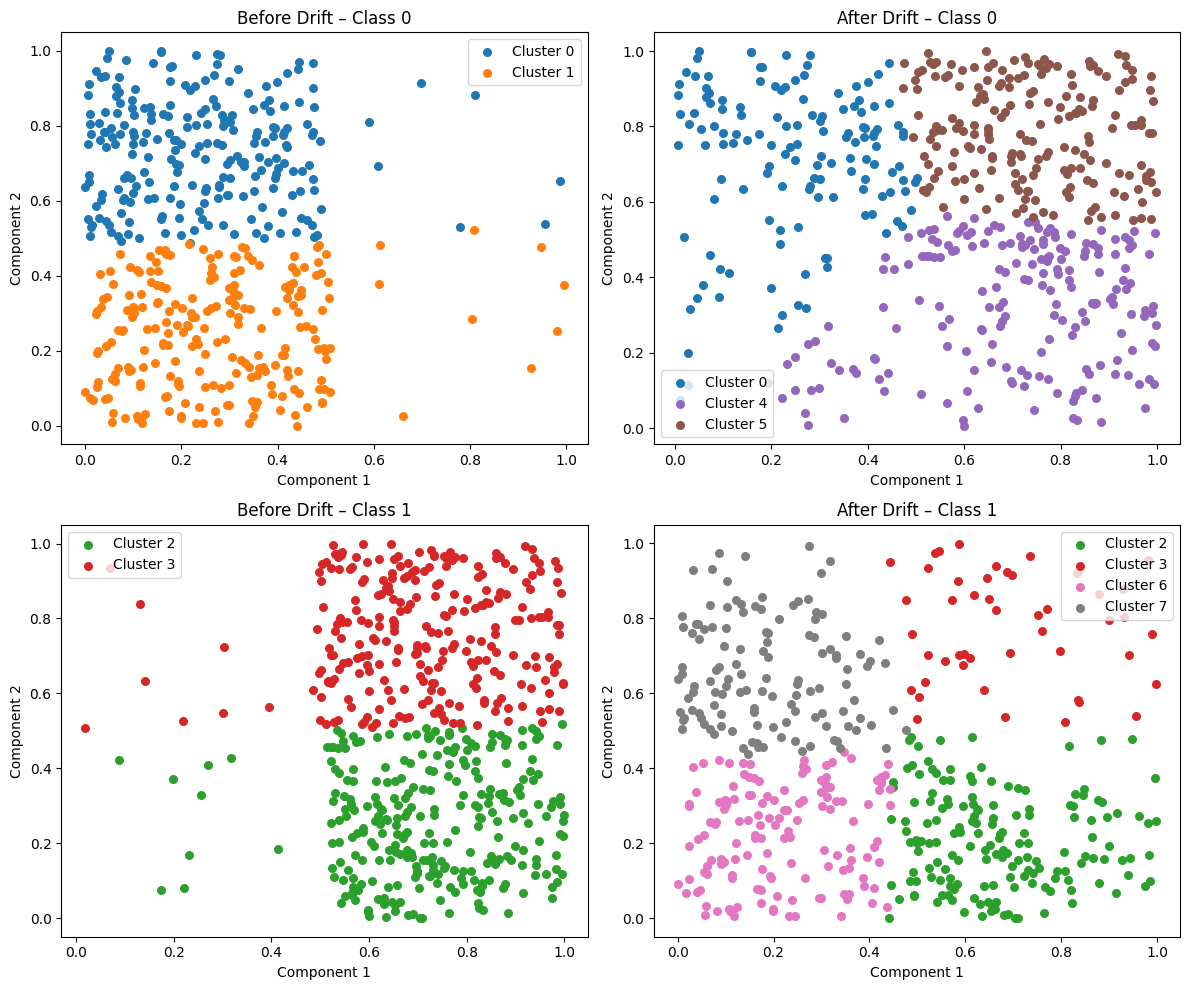

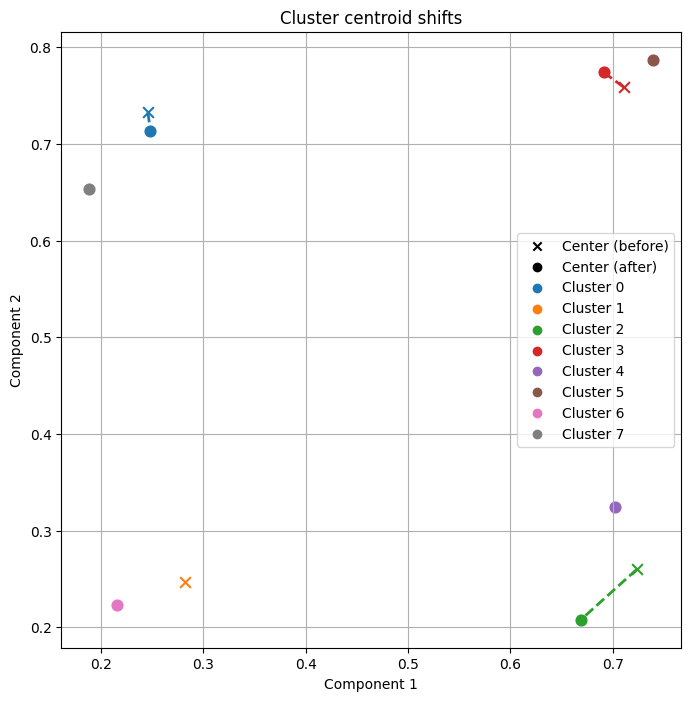

In [15]:
_ = run_experiment("Hyperplane 2D", "hyperplane_drift", n_features=2, n_drift_features=2)

In two dimensions the structural change is visible directly:

* class 0 lost its lower-left cluster 1 and appeared on the right (clusters 4 and 5);
* class 1 appeared on the left (clusters 6 and 7);
* class 1's upper-right cluster 3 shrank from 257 to 47 samples.

The boundary between the classes has rotated.

**2. Hyperplane 3D, all features drift**

**Drift detected: True** — strength 0.826, p-value 0.020, 95th percentile without drift 0.019

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,2/2,5/18,2/2
1,True,2/2,6/18,2/2


,class,n before,n after,status
cluster,,,,
0,0,226,0,disappeared
1,0,218,131,tracked
2,0,297,353,tracked
3,0,275,0,disappeared
4,1,288,247,tracked
5,1,266,299,tracked
6,1,205,0,disappeared
7,1,225,0,disappeared
8,0,0,531,appeared


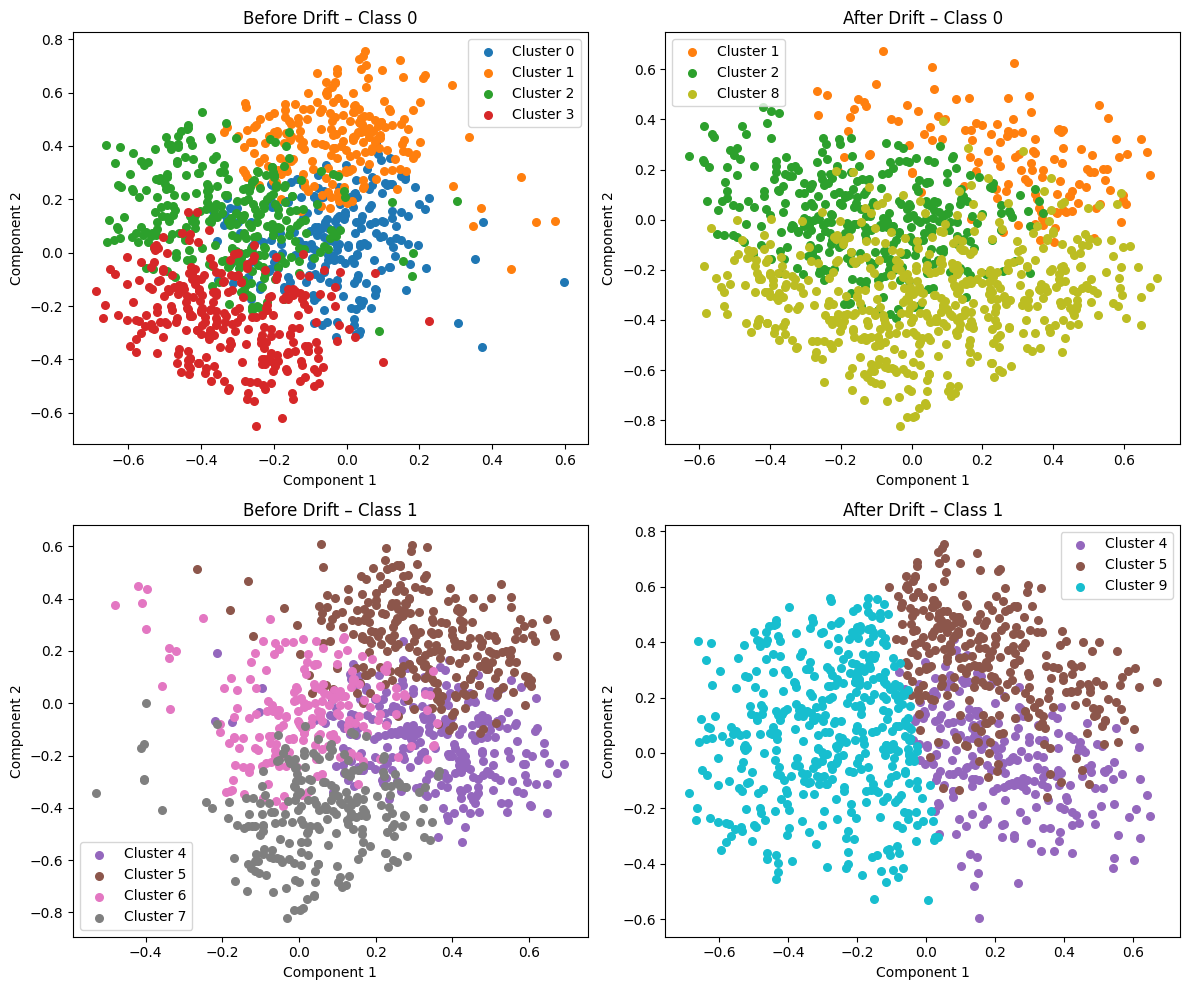

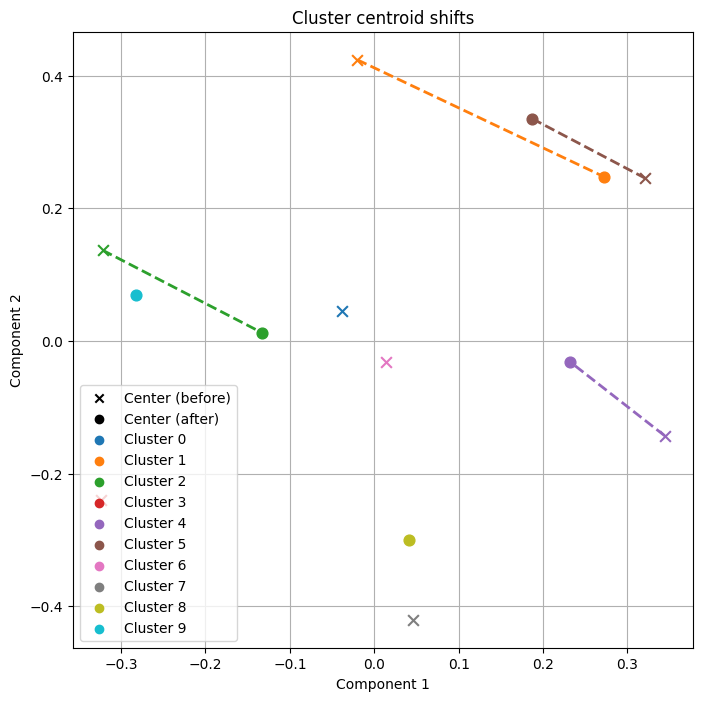

In [16]:
_ = run_experiment("Hyperplane 3D, 3 drifting", "hyperplane_drift", size_of_block=2000, n_features=3, n_drift_features=3)

Strong structural change in both classes: four reference clusters disappeared and two new ones appeared. The tracked clusters moved by 0.7–1.5, mainly along `X1` (mean shift up to 1.45σ, below 0.12σ for `X2` and `X3`).

**3. Hyperplane 3D, 2 of 3 features drift**

**Drift detected: True** — strength 0.756, p-value 0.020, 95th percentile without drift 0.014

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,2/2,4/18,1/2
1,True,0/0,0/0,0/0


,class,n before,n after,status
cluster,,,,
0,0,265,321,tracked
1,0,286,173,tracked
2,0,198,0,disappeared
3,0,250,0,disappeared
4,1,209,0,disappeared
5,1,284,0,disappeared
6,1,315,0,disappeared
7,1,193,0,disappeared
8,0,0,503,appeared


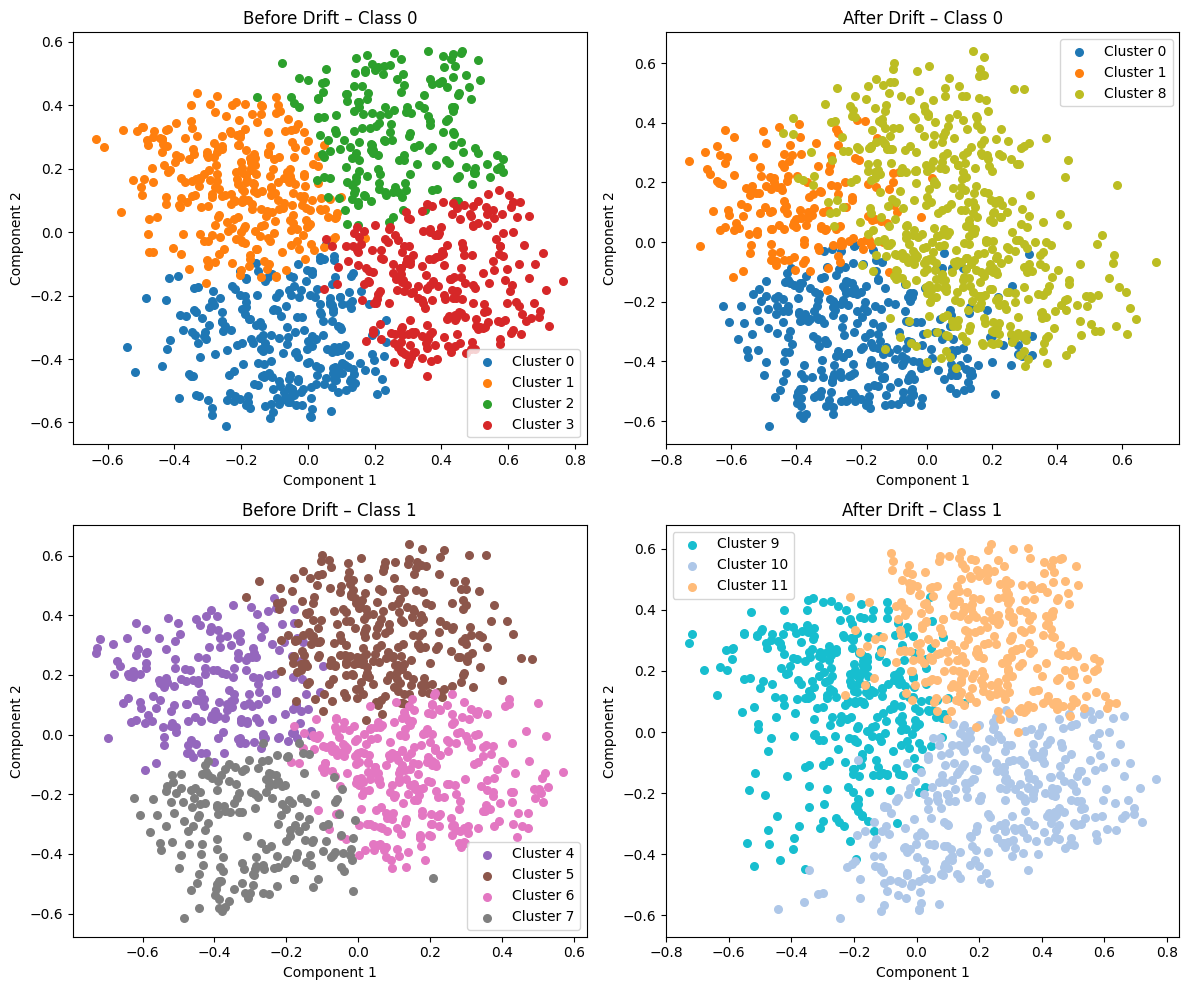

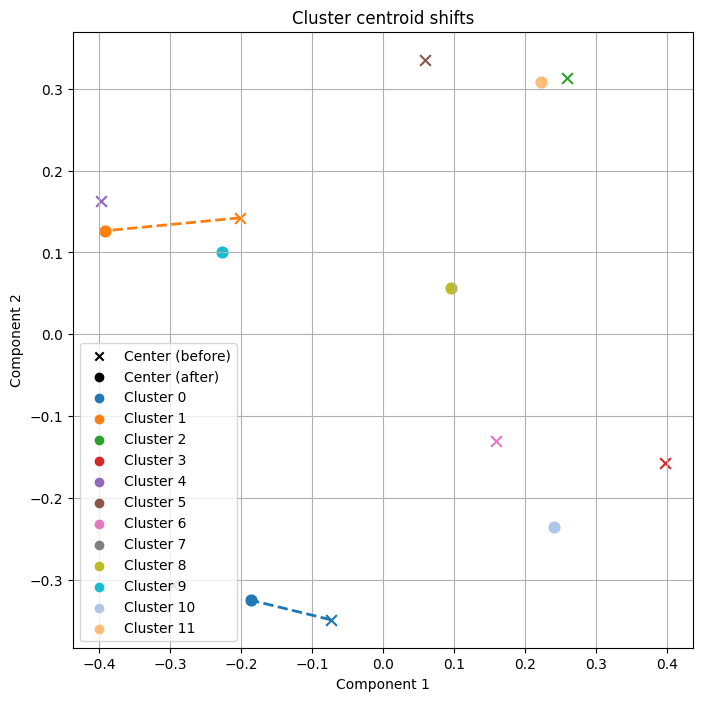

In [17]:
_ = run_experiment("Hyperplane 3D, 2 drifting", "hyperplane_drift", size_of_block=2000, n_features=3, n_drift_features=2)

* In class 1 all four reference clusters disappeared and three new ones appeared, so no cluster of class 1 is tracked (0/0 evaluated checks). Class 1 occupies a different part of the space than before.
* Class 0 kept two clusters, lost two and gained one.

**4. Hyperplane 5D, 2 of 5 features drift**

**Drift detected: True** — strength 0.404, p-value 0.020, 95th percentile without drift 0.025

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,False,2/2,18/30,1/2
1,False,2/2,13/30,0/2


,class,n before,n after,status
cluster,,,,
0,0,226,298,tracked
1,0,278,226,tracked
2,1,265,246,tracked
3,1,231,230,tracked


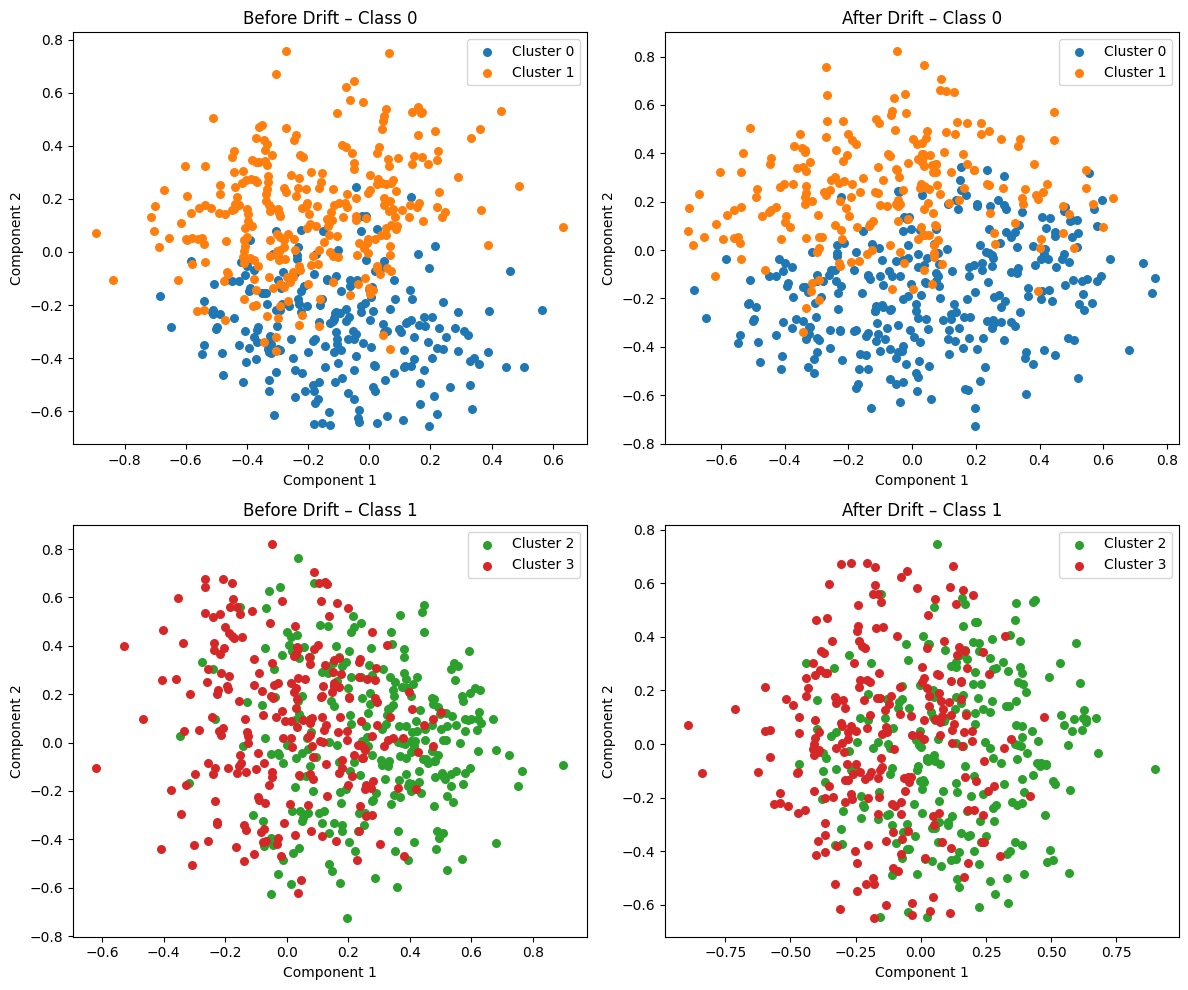

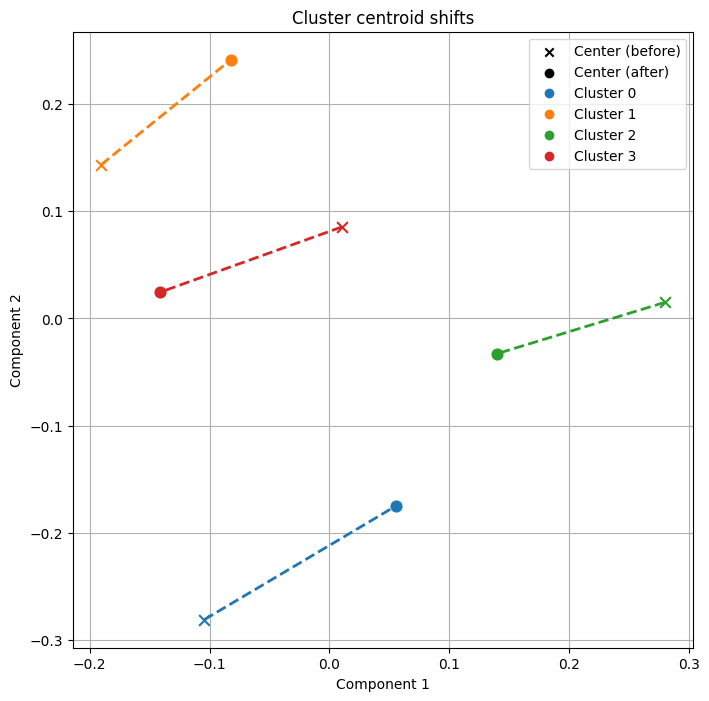

In [18]:
_ = run_experiment("Hyperplane 5D, 2 drifting", "hyperplane_drift", n_features=5, n_drift_features=2)

* With 5 features the drift does not change the cluster structure: 4 clusters, all tracked.
* All four centroids shifted, by 0.85–1.03 against a threshold of 0.34.
* Most per-cluster statistics changed (18/30 and 13/30). The largest mean shifts are in `X1` and `X5` (up to 0.76σ and 0.70σ), `X2` follows (0.39σ), and `X3` and `X4` change least (below 0.2σ).
* The features themselves do not change, so these shifts show which features separate the classes differently after the drift.

### 4.2. SEA

The class is given by $x_1 + x_2 \le \theta$; the drift changes the threshold $\theta$ (SEA variant 0 → 3). The third feature is irrelevant noise. As for Hyperplane, the feature values after the drift equal those before it; only the labels change.

**1. SEA, only the relevant features**

**Drift detected: True** — strength 0.217, p-value 0.020, 95th percentile without drift 0.025

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
False,False,2/2,4/12,2/2
True,False,0/2,0/12,0/2


,class,n before,n after,status
cluster,,,,
0,False,143,209,tracked
1,False,158,222,tracked
2,True,397,321,tracked
3,True,302,248,tracked


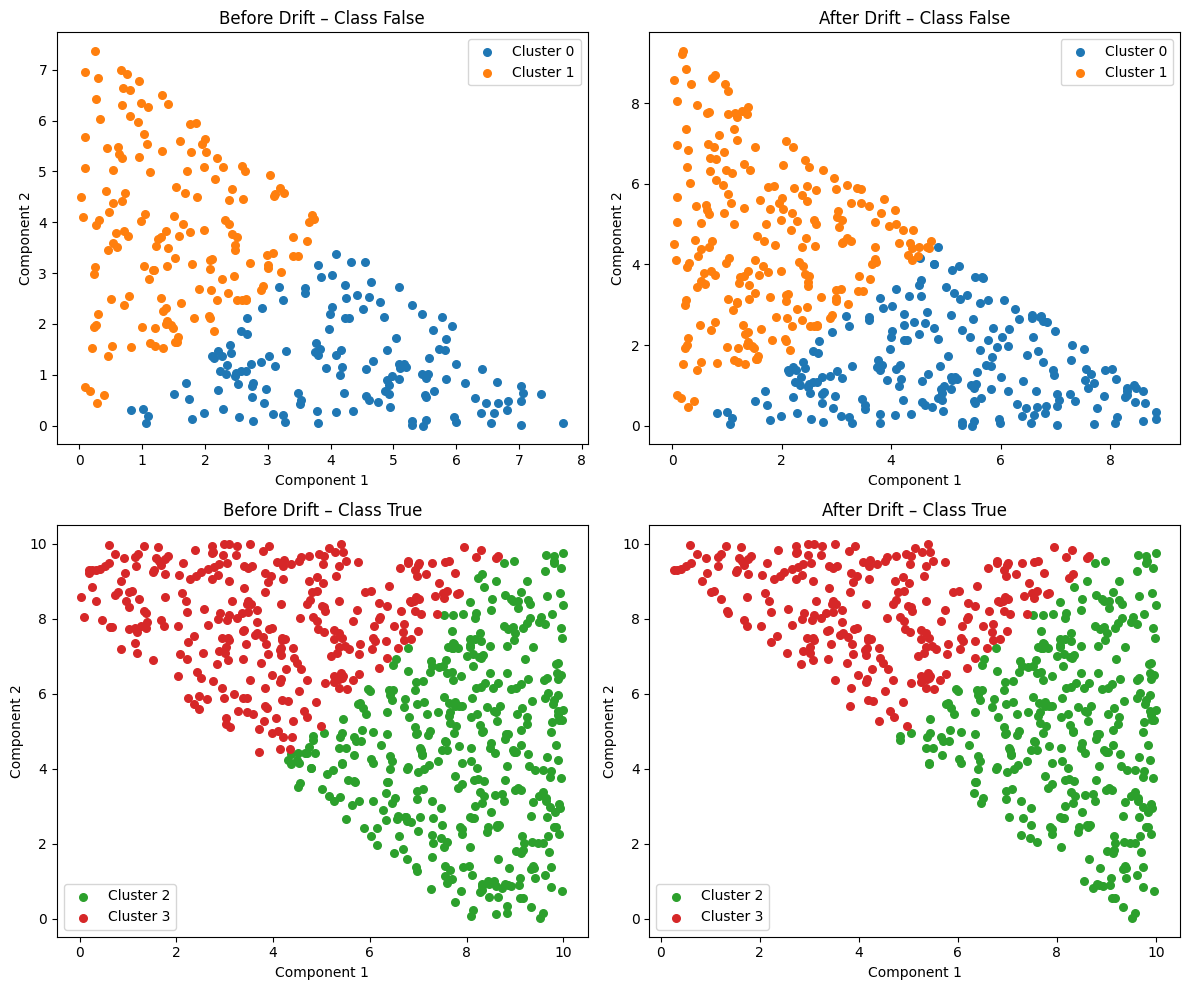

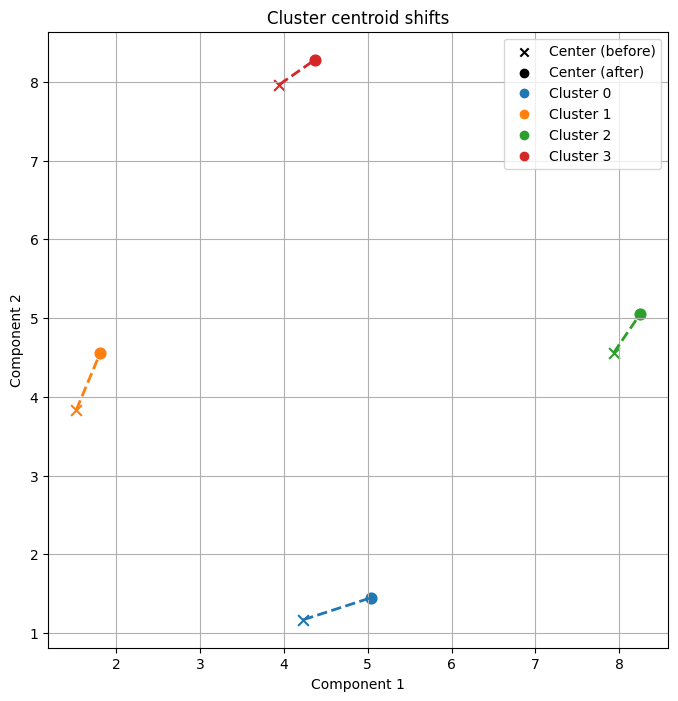

In [19]:
_ = run_experiment("SEA, relevant features", "sea_drift", n_features=2)

* The structure is unchanged (4 tracked clusters).
* Class `False` grows into a larger region: both of its clusters gained samples (143 → 209, 158 → 222), shifted beyond the threshold and widened by about 23%.
* Class `True` barely changes (0 of 16 checks).
* The strength is small (0.22), yet above the 95th percentile without drift (0.025): a weak but clearly significant drift.

**2. SEA, all features (including the irrelevant one)**

**Drift detected: True** — strength 0.101, p-value 0.020, 95th percentile without drift 0.031

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
False,False,1/2,1/18,2/2
True,False,0/3,1/27,0/3


,class,n before,n after,status
cluster,,,,
0,False,155,210,tracked
1,False,146,221,tracked
2,True,244,217,tracked
3,True,247,194,tracked
4,True,208,158,tracked


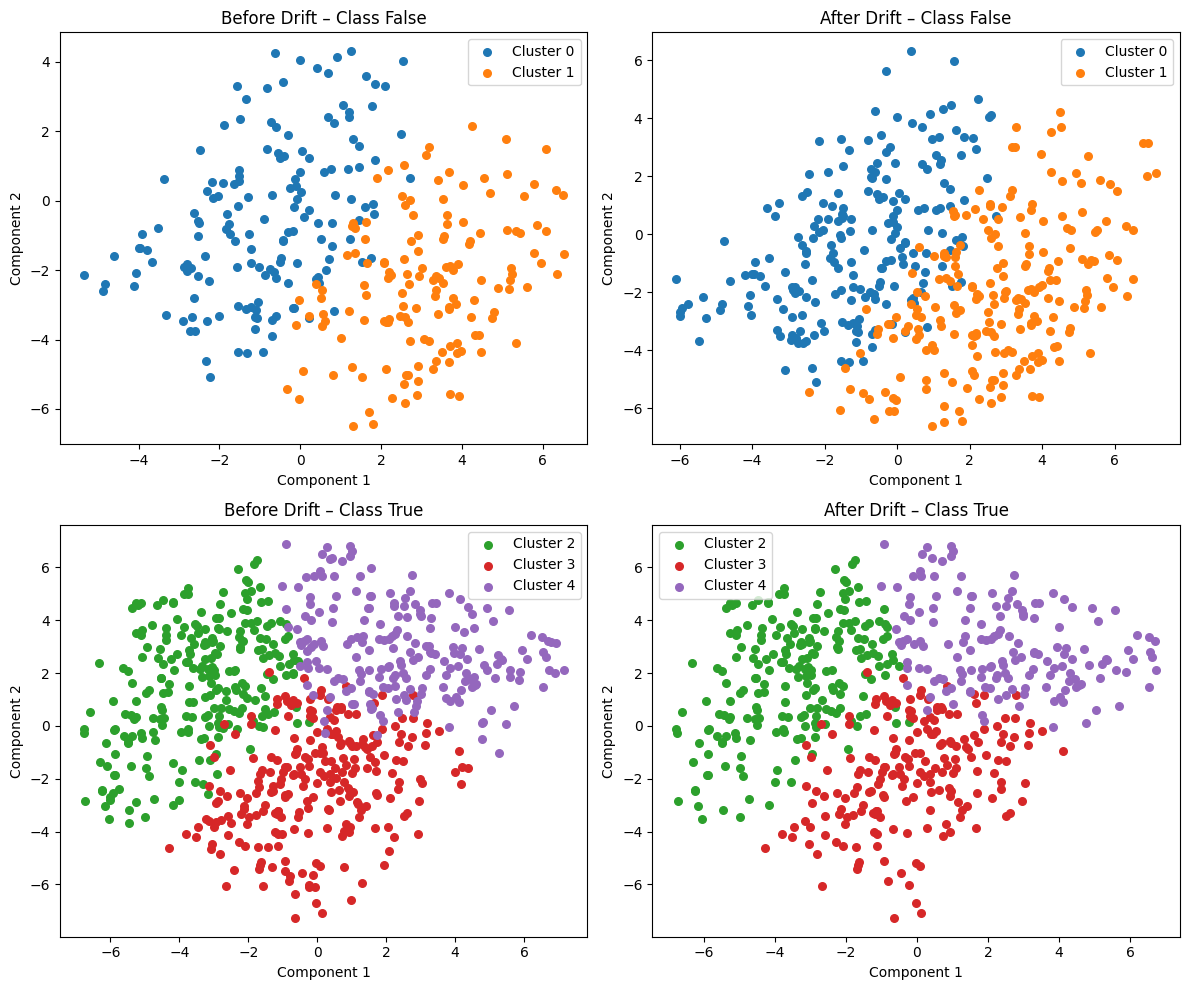

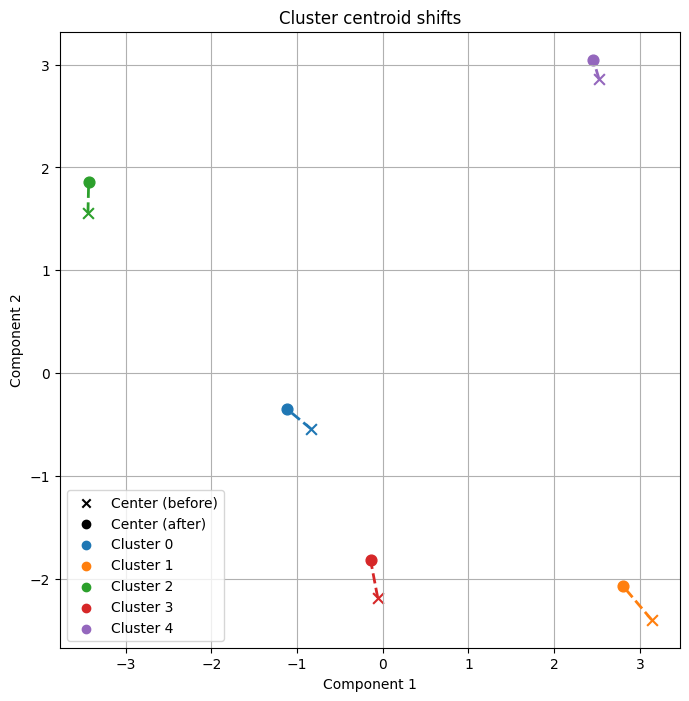

In [20]:
_ = run_experiment("SEA, all features", "sea_drift", n_features=3)

* Adding the irrelevant feature `X3` dilutes the signal. X-Means finds one more cluster in class `True`, which adds checks that are not triggered, and `X3` itself changes by less than 0.04σ in every cluster.
* The strength drops to 0.10, but the 95th percentile without drift also drops (0.03), so the drift is still detected.
* This is why the decision is made by the permutation test rather than by a fixed threshold on the strength.

### 4.3. RBF

Each class is a mixture of Gaussian blobs; the drift swaps the class assignment of the blobs.

**Drift detected: True** — strength 1.000, p-value 0.020, 95th percentile without drift 0.013

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,0/0,0/0,0/0
1,True,0/0,0/0,0/0


,class,n before,n after,status
cluster,,,,
0,0,261,0,disappeared
1,0,241,0,disappeared
2,1,257,0,disappeared
3,1,241,0,disappeared
4,0,0,251,appeared
5,0,0,252,appeared
6,1,0,253,appeared
7,1,0,244,appeared


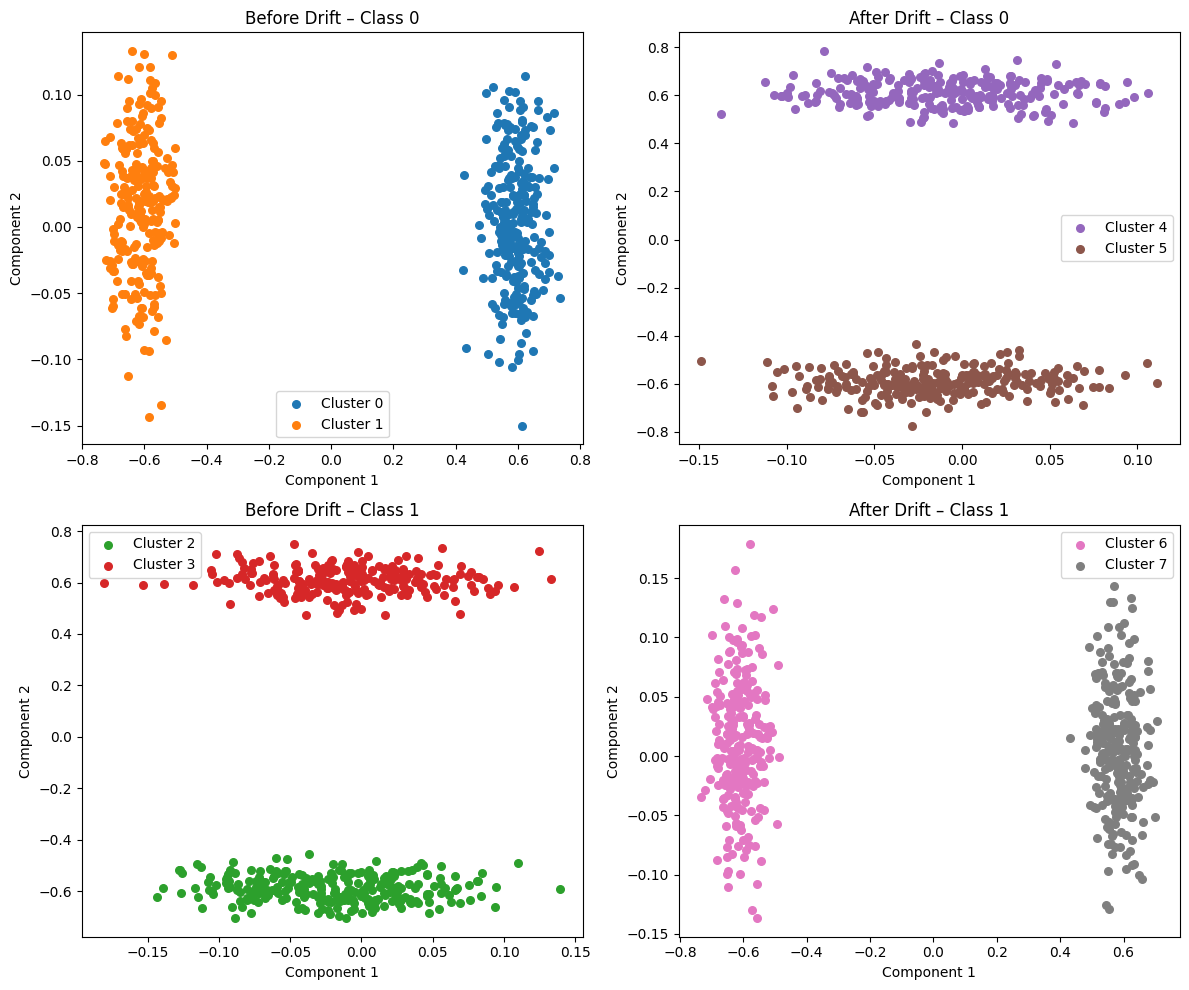

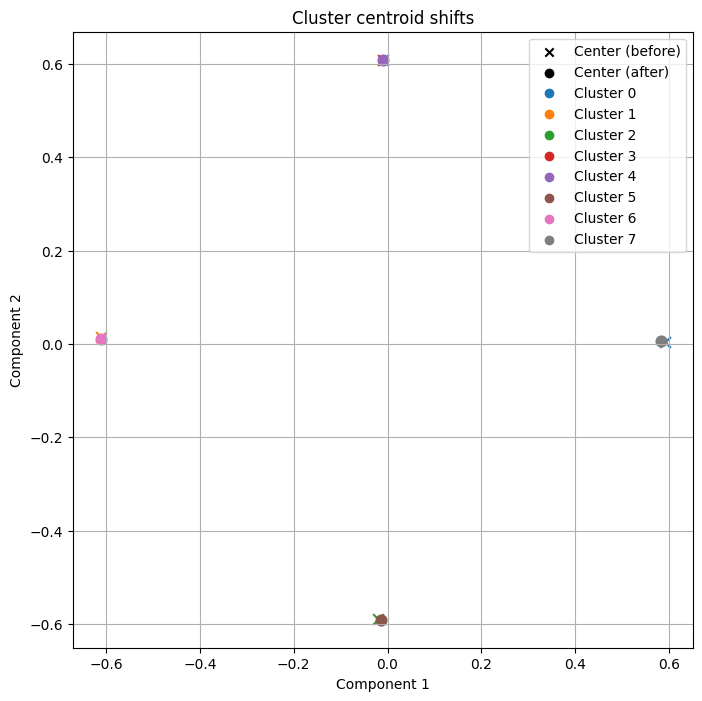

In [21]:
_ = run_experiment("RBF", "rbf_drift")

* The drift swaps the class assignment of the RBF blobs: every reference cluster disappeared and every detection cluster appeared. All checks are triggered, so the strength is 1.0.
* The per-class marginals of the features do not change, so per-feature statistics or tests do not see this drift (see `clustering_experiments.ipynb`).

### 4.4. Linear Weight Inversion

The features are uniform on $[0, 1]$ and do not drift. The label is 1 when a linear combination of the features exceeds its median; the drift inverts the weights of the first `n_drift_features` features from +1 to −1.

**1. 2 features, both drift**

**Drift detected: True** — strength 1.000, p-value 0.020, 95th percentile without drift 0.023

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,True,0/0,0/0,0/0
1,True,0/0,0/0,0/0


,class,n before,n after,status
cluster,,,,
0,0,141,0,disappeared
1,0,84,0,disappeared
2,0,132,0,disappeared
3,0,137,0,disappeared
4,1,232,0,disappeared
5,1,274,0,disappeared
6,0,0,164,appeared
7,0,0,192,appeared
8,0,0,142,appeared


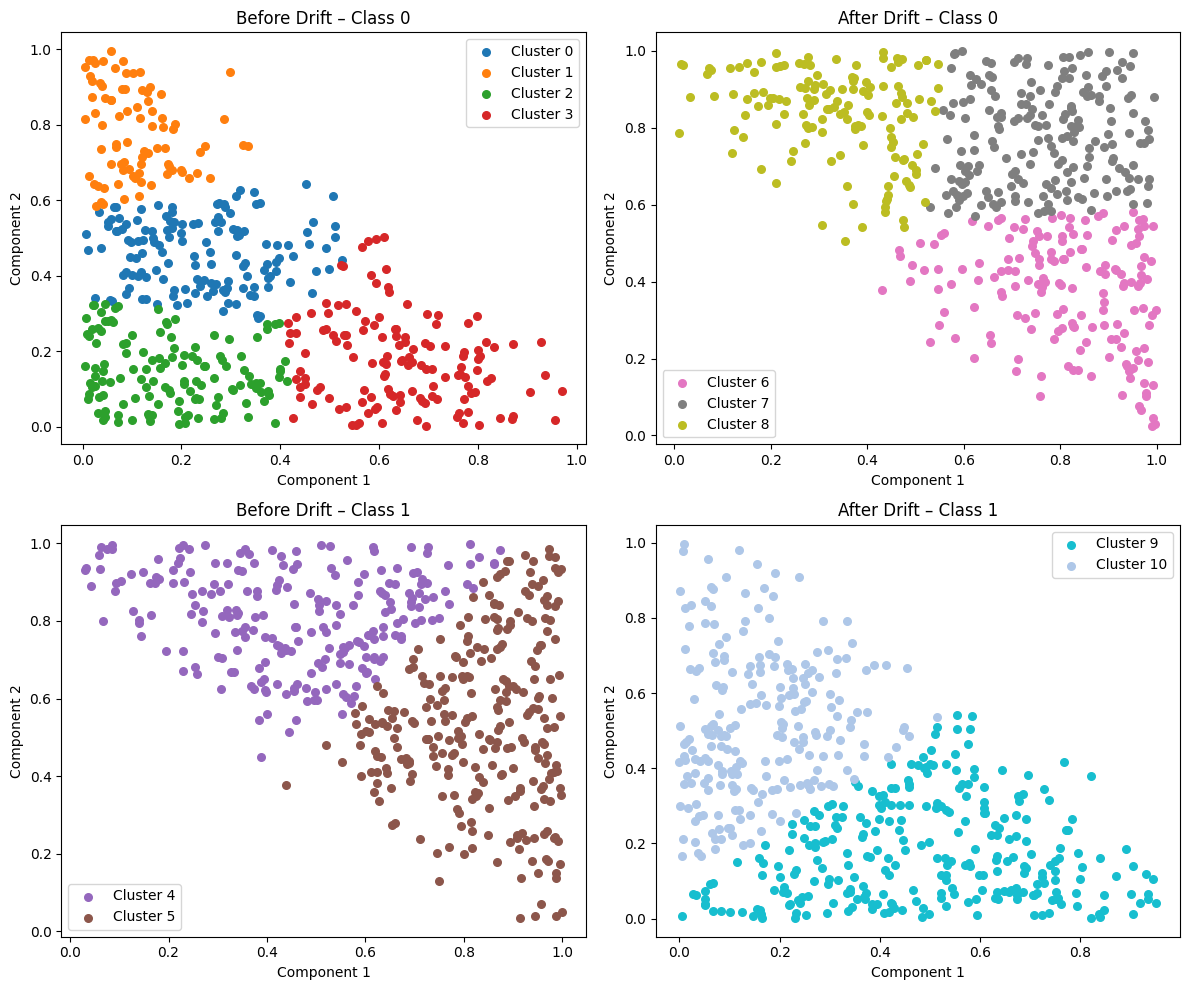

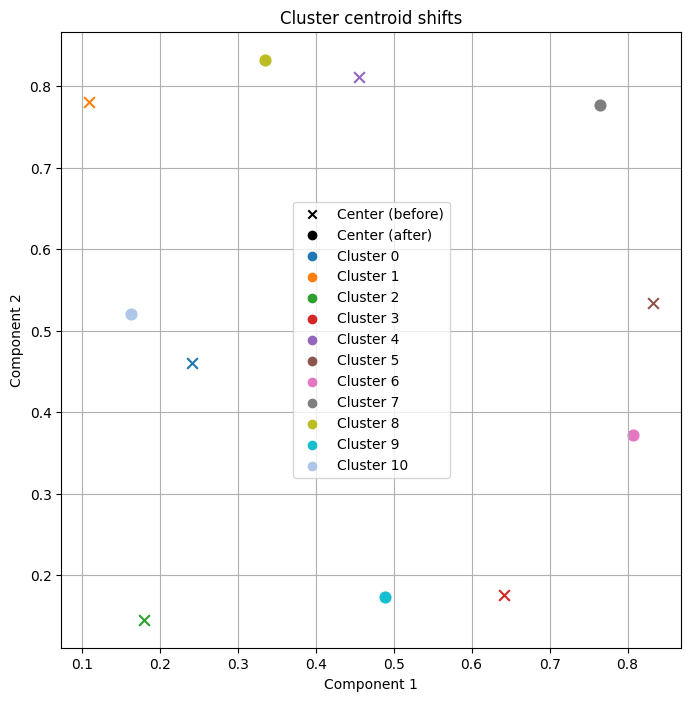

In [22]:
_ = run_experiment("LWI 2D, 2 drifting", "linear_weight_inversion_drift", n_features=2, n_drift_features=2)

* With both features inverted the classes swap their triangles of the unit square: class 0 moved from the region of small $x_1 + x_2$ to that of large $x_1 + x_2$.
* Every reference cluster disappeared and new ones appeared (strength 1.0).

**2. 4 features, 2 drift**

**Drift detected: True** — strength 0.410, p-value 0.020, 95th percentile without drift 0.021

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,False,2/2,14/24,1/2
1,False,2/2,12/24,0/2


,class,n before,n after,status
cluster,,,,
0,0,281,154,tracked
1,0,212,335,tracked
2,1,235,303,tracked
3,1,272,208,tracked


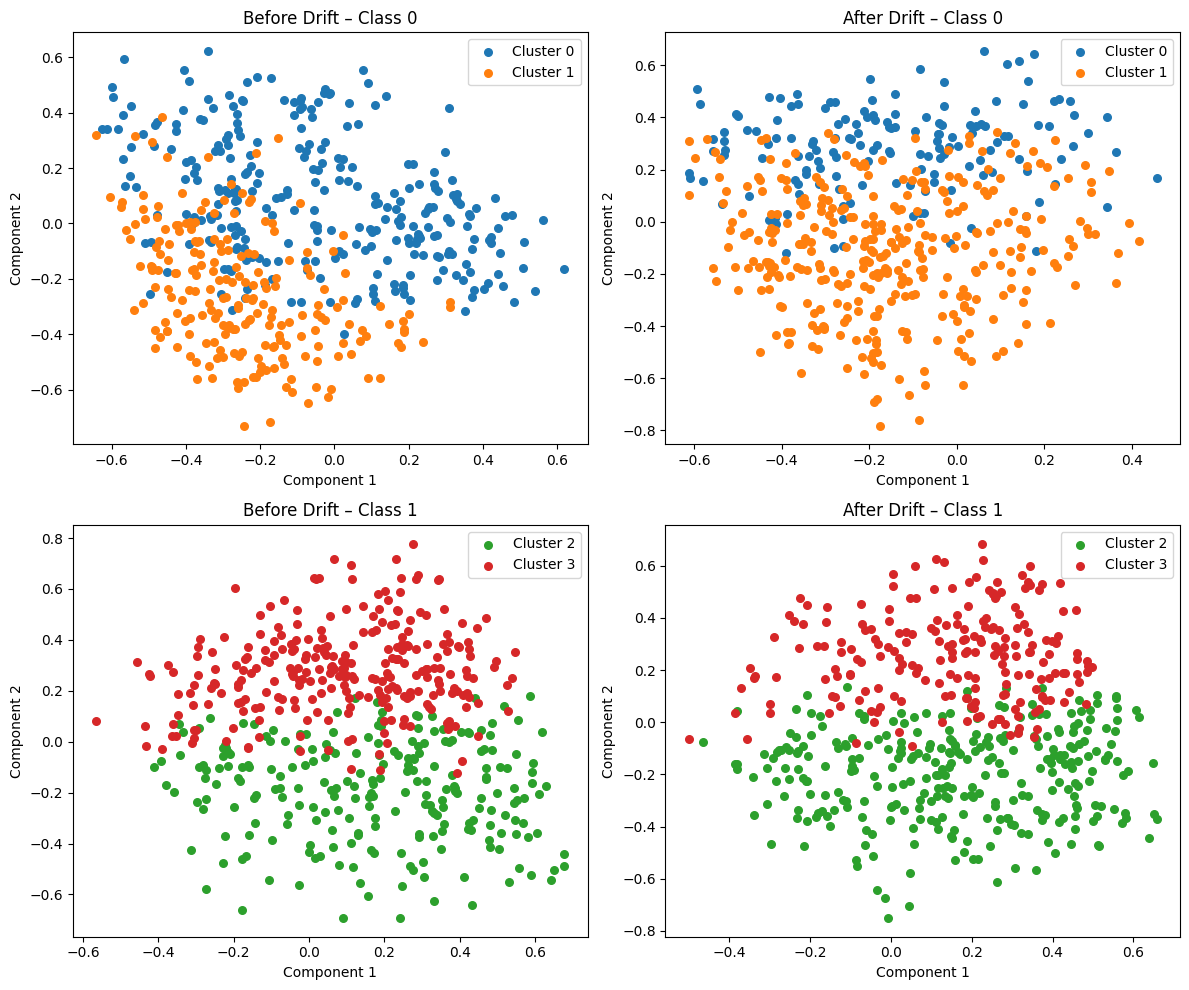

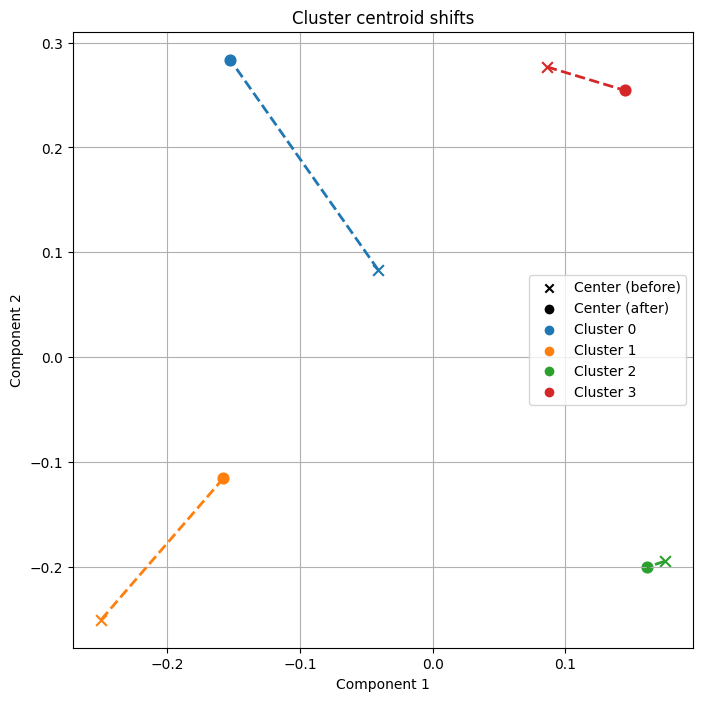

In [23]:
_ = run_experiment("LWI 4D, 2 drifting", "linear_weight_inversion_drift", n_features=4, n_drift_features=2)

* With half of the features inverted the structure is kept (4 tracked clusters), and the clusters move instead.
* The centroid shifts are 0.93–1.24 against a threshold of 0.30.
* The per-cluster statistics attribute the change to the inverted features `X1` and `X2` (mean shift 0.78σ and 0.65σ on average) rather than to `X3` and `X4` (0.17σ).

**3. 11 features, 5 drift (default parameters)**

**Drift detected: True** — strength 0.337, p-value 0.020, 95th percentile without drift 0.021

,clusters appeared/disappeared,centroid shift,descriptive statistics,spread
class,,,,
0,False,2/2,24/66,0/2
1,False,2/2,22/66,0/2


,class,n before,n after,status
cluster,,,,
0,0,249,188,tracked
1,0,273,296,tracked
2,1,260,310,tracked
3,1,218,206,tracked


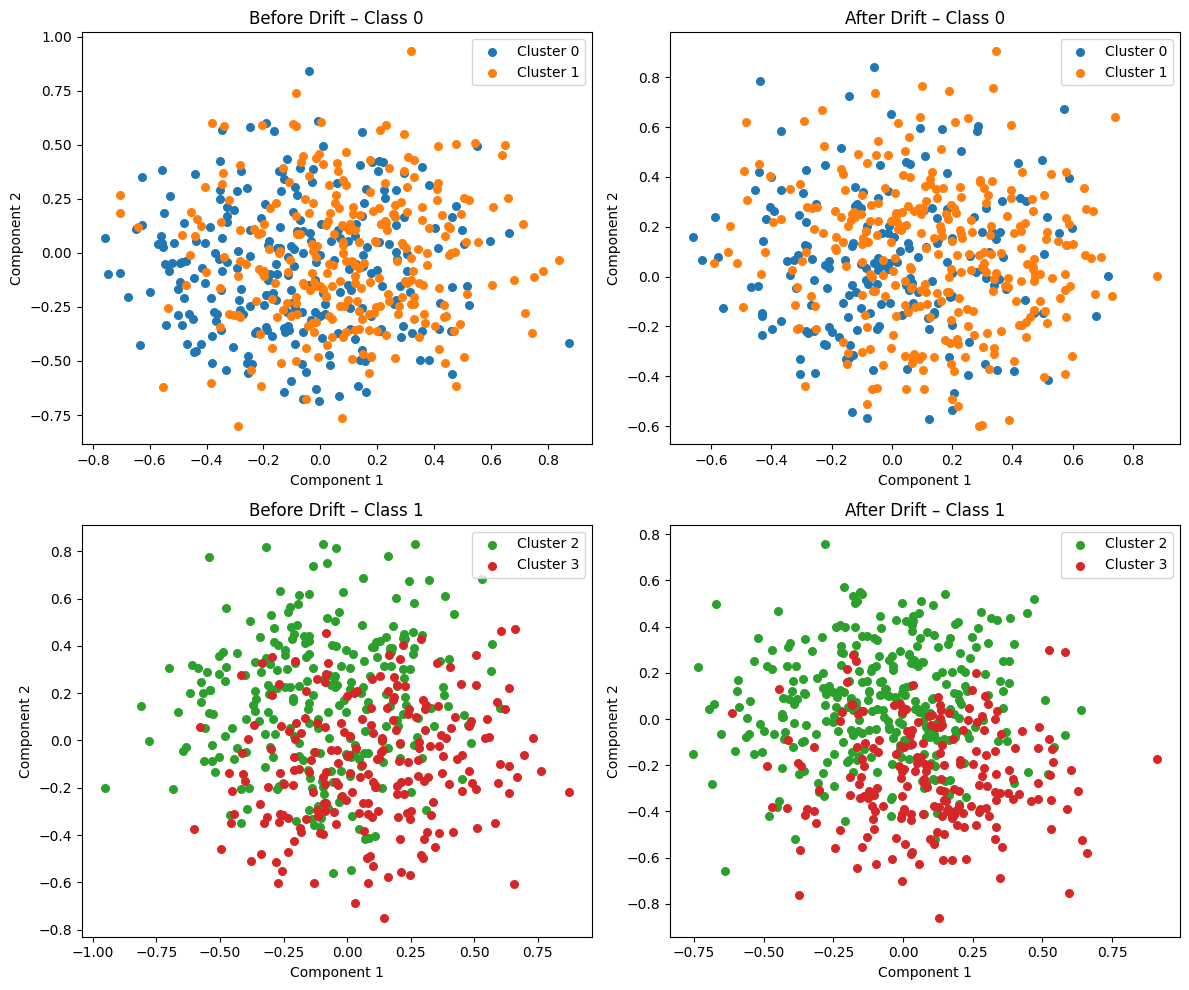

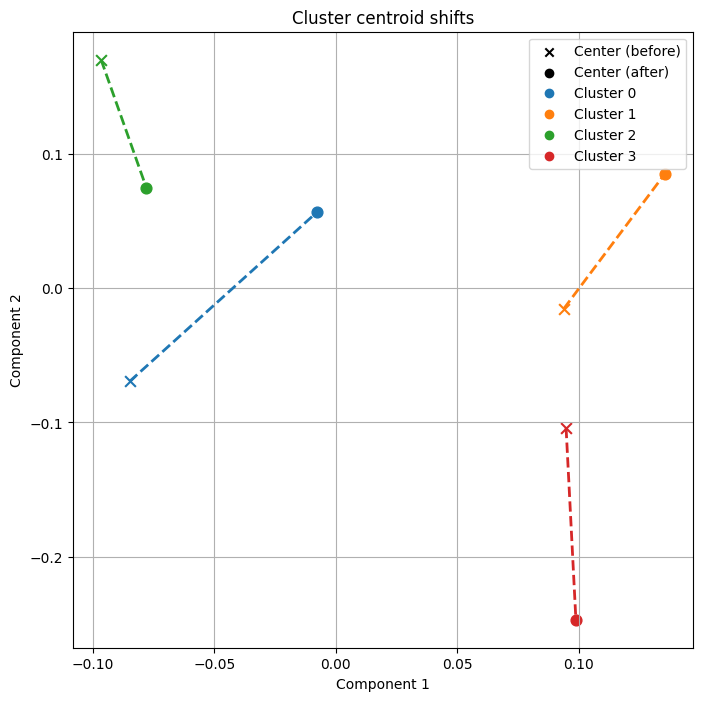

In [24]:
_ = run_experiment("LWI 11D, 5 drifting", "linear_weight_inversion_drift", n_features=11, n_drift_features=5)

* As with 4 features, the structure is kept and all four centroids move (1.05–1.36 against 0.50).
* The per-cluster statistics single out the five inverted features `X1`–`X5` (see `clustering_experiments.ipynb` for the per-feature table).

## 5. Summary

In [25]:
pd.DataFrame(SUMMARY).T.style.format(precision=3)

,features,drift detected,strength,p-value,95th pct without drift,clusters before,appeared,disappeared
Hyperplane 2D,2,True,0.558,0.020,0.037,4,4,1
"Hyperplane 3D, 3 drifting",3,True,0.826,0.020,0.019,8,2,4
"Hyperplane 3D, 2 drifting",3,True,0.756,0.020,0.014,8,4,6
"Hyperplane 5D, 2 drifting",5,True,0.404,0.020,0.025,4,0,0
"SEA, relevant features",2,True,0.217,0.020,0.025,4,0,0
"SEA, all features",3,True,0.101,0.020,0.031,5,0,0
RBF,4,True,1.000,0.020,0.013,4,4,4
"LWI 2D, 2 drifting",2,True,1.000,0.020,0.023,6,5,6
"LWI 4D, 2 drifting",4,True,0.410,0.020,0.021,4,0,0
"LWI 11D, 5 drifting",11,True,0.337,0.020,0.021,4,0,0


**Summary**

* The detector flags drift in all ten settings. In every case the observed strength is above all 50 permuted strengths, hence p = 0.02.
* The **type of explanation depends on how much of the space changes**:
  * when the drift rearranges the classes completely (Hyperplane 2D/3D, RBF, LWI 2D), clusters appear and disappear;
  * when it moves them partially (Hyperplane 5D, SEA, LWI 4D/11D), the clusters are tracked, and the centroid shifts and per-cluster statistics point to the features involved.
* The raw strength ranges from 0.10 to 1.0 and its value without drift varies between settings (95th percentile 0.013–0.037). A single fixed threshold would not work for all of them; the permutation test calibrates the decision for each one.
* Single seed (`random_seed=42`): an illustration of the explanations, not an evaluation of detection rates.